In [1]:
import pandas as pd
import numpy as np
import torch
from torch.utils.data import TensorDataset, DataLoader

In [2]:
df = pd.read_csv('PoliticalDemocracy.csv')
var_names = df.columns.values.tolist()
dataset = torch.tensor(df.to_numpy()).to(dtype = torch.float32)
batch_size = 25
dataloader = DataLoader(TensorDataset(dataset), batch_size = batch_size, shuffle = True)

In [3]:
observation = next(iter(dataloader))
print(observation)

[tensor([[ 2.5000,  3.3333,  3.3333,  3.3333,  6.2500,  3.3333,  3.3333,  3.3333,
          5.5215,  5.2417,  4.1152],
        [ 7.5000, 10.0000, 10.0000, 10.0000,  8.7500, 10.0000, 10.0000, 10.0000,
          6.7370,  7.1253,  6.3305],
        [ 2.5000,  0.0000,  6.6667,  3.3333,  5.0000,  0.0000,  6.6667,  3.3333,
          5.3936,  5.6384,  4.1695],
        [ 5.0000,  0.0000,  3.3333,  3.3333,  5.0000,  0.0000,  3.3333,  3.3333,
          5.1818,  4.3944,  3.1672],
        [ 8.9000,  8.8000, 10.0000,  9.2000,  8.9079,  8.1280, 10.0000,  4.6151,
          6.2860,  7.5679,  6.2675],
        [10.0000,  3.3333, 10.0000,  6.6667,  7.5000,  3.3333, 10.0000,  6.6667,
          5.8636,  6.8189,  4.5737],
        [ 8.9000, 10.0000,  9.7000,  6.6667,  5.0000, 10.0000,  9.5560,  6.6667,
          4.5326,  3.6109,  1.5878],
        [ 5.2000,  5.0000,  6.6000,  3.3333,  3.6334,  1.1000,  3.3141,  3.3333,
          5.5645,  5.2364,  2.6776],
        [ 7.5000,  3.3333,  6.6667,  6.6667,  6.2500,  

In [4]:
print(var_names)

['y1', 'y2', 'y3', 'y4', 'y5', 'y6', 'y7', 'y8', 'x1', 'x2', 'x3']


In [5]:
from torch import nn

In [6]:
tmp = [nn.Linear(1 + 1, 1) for i in range(3)]
tmp[0] is tmp[1]

False

In [7]:
class LinearFactor(nn.Module):    
    """Modified from engression.models.StoLayer.

    Args:
        in_dim (int): input dimension 
        out_dim (int): output dimension
    """
    def __init__(self, in_dim, out_dim):
        super().__init__()
        self.in_dim = in_dim
        self.out_dim = out_dim     
        self.layers = nn.ModuleList([nn.Linear(in_dim + 1, 1) for i in range(out_dim)])
    
    def forward(self, x):
        # device = next(self.layer.parameters()).device
        if x.size(1) != self.in_dim:
            raise ValueError("Input dimension does not match.")
        else:
            eps = torch.randn(x.size(0), self.out_dim)
            x = torch.cat([self.layers[i](torch.cat((x, eps[:,i,None]), 1)) 
                           for i in range(self.out_dim)], 1)
        return x

In [15]:
x = dataset[:, -3:]
n = x.size(0)
print(n)

75


In [26]:
from engression.loss_func import energy_loss_two_sample
model = LinearFactor(1, 3)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-2)
model.train()
for i in range(1000):
    optimizer.zero_grad()
    z1 = torch.randn(n, 1)    
    z2 = torch.randn(n, 1)
    sample1 = model(z1)
    sample2 = model(z2)
    loss, s1, s2 = energy_loss_two_sample(x, sample1, sample2)
    loss.backward()
    optimizer.step()
    if i == 0 or (i + 1) % 100 == 0:
        print(f'Iter {i + 1} | loss: {loss.item():.4f}, s1: {s1.item():.4f}, s2: {s2.item():.4f}')

Iter 1 | loss: 7.6645, s1: 8.2977, s2: 1.2665
Iter 100 | loss: 5.4291, s1: 7.2477, s2: 3.6372
Iter 200 | loss: 3.5150, s1: 6.0540, s2: 5.0779
Iter 300 | loss: 3.1396, s1: 5.9321, s2: 5.5852
Iter 400 | loss: 1.9214, s1: 4.7037, s2: 5.5646
Iter 500 | loss: 1.7554, s1: 3.9535, s2: 4.3961
Iter 600 | loss: 1.4453, s1: 3.2388, s2: 3.5870
Iter 700 | loss: 1.2622, s1: 2.7661, s2: 3.0079
Iter 800 | loss: 1.2817, s1: 2.6456, s2: 2.7277
Iter 900 | loss: 1.5639, s1: 2.9922, s2: 2.8565
Iter 1000 | loss: 1.2037, s1: 2.7188, s2: 3.0302


In [27]:
[model.layers[i].weight for i in range(3)]

[Parameter containing:
 tensor([[-0.7183, -0.1642]], requires_grad=True),
 Parameter containing:
 tensor([[-1.3774,  0.5952]], requires_grad=True),
 Parameter containing:
 tensor([[-1.3068,  0.8135]], requires_grad=True)]

In [28]:
beta = [model.layers[i].weight[0][0].detach().numpy().tolist() for i in range(3)]

In [29]:
[beta[i] / beta[0] for i in range(3)]

[1.0, 1.9176105477245702, 1.819353869720101]

In [30]:
z = torch.randn(n * 100, 1)    
sample = model(z)
sample_df = pd.DataFrame(sample.detach().numpy(), columns = ["x1", "x2", "x3"])

<Axes: ylabel='Frequency'>

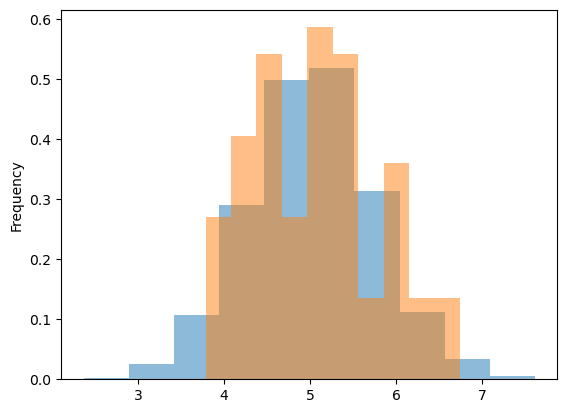

In [35]:
sample_df["x1"].plot.hist(alpha = 0.5, density = True)
df["x1"].plot.hist(alpha = 0.5, density = True)

<Axes: ylabel='Frequency'>

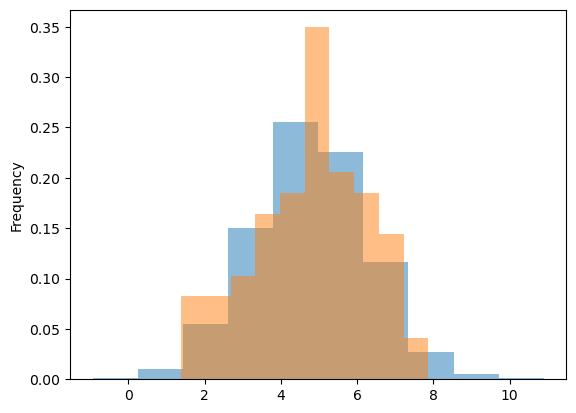

In [32]:
sample_df["x2"].plot.hist(alpha = 0.5, density = True)
df["x2"].plot.hist(alpha = 0.5, density = True)

<Axes: ylabel='Frequency'>

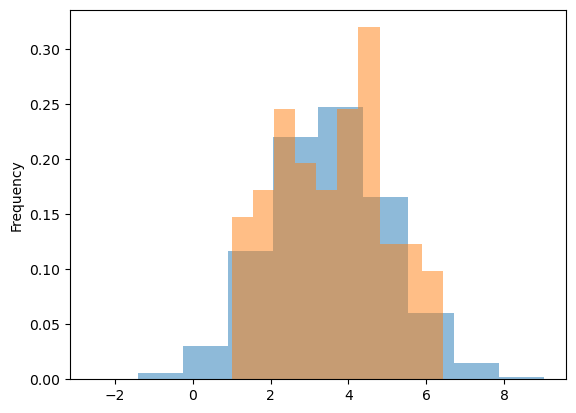

In [33]:
sample_df["x3"].plot.hist(alpha = 0.5, density = True)
df["x3"].plot.hist(alpha = 0.5, density = True)